## Noah Smith - HOMEWORK ASSIGNMENT 1!!!!!

**_Question #1_**

h = 0.1
Forward derivative = 0.4973637525353891
Centered derivative = 0.53940225216976
Forward error = 0.04293855333275065
Centered error = 0.0009000536983797547

h = 0.01
Forward derivative = 0.536085981011869
Centered derivative = 0.5402933008747335
Forward error = 0.00421632485627077
Centered error = 9.004993406280803e-06

h = 0.001
Forward derivative = 0.5398814803603269
Centered derivative = 0.5403022158177451
Forward error = 0.0004208255078128609
Centered error = 9.00503946965614e-08

h = 0.0001
Forward derivative = 0.5402602314186211
Centered derivative = 0.5403023049677103
Forward error = 4.207444951864758e-05
Centered error = 9.004295087322589e-10

h = 1e-05
Forward derivative = 0.5402980985058647
Centered derivative = 0.5403023058569989
Forward error = 4.207362275021609e-06
Centered error = 1.1140866007508521e-11

h = 1e-06
Forward derivative = 0.5403018851213304
Centered derivative = 0.5403023058958567
Forward error = 4.2074680939307996e-07
Centered error = 2.771693985437195

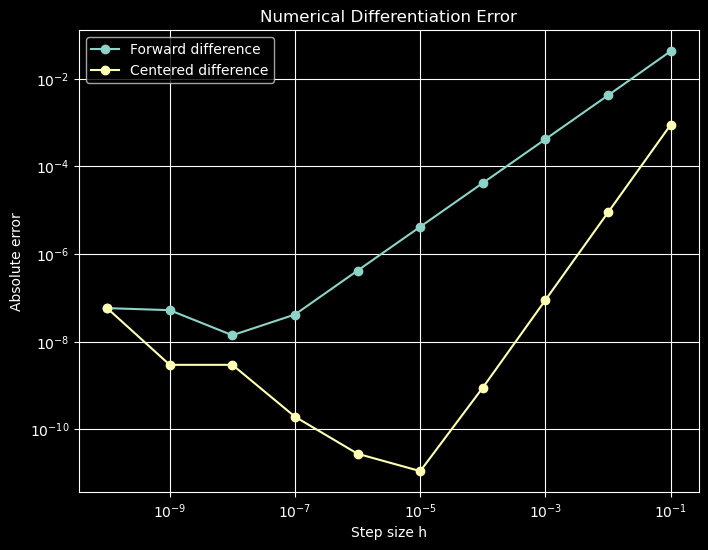

In [1]:
import numpy as np
import matplotlib.pyplot as plt


def example_function(x):
    return np.sin(x)


x0 = 1.0
exact_derivative = np.cos(x0)
h_values = 10.0 ** (-np.arange(1, 11))

forward_errors = []
centered_errors = []

for h in h_values:
    #derivatives
    forward_derivative = (example_function(x0 + h) - example_function(x0)) / h
    centered_derivative = (example_function(x0 + h) - example_function(x0 - h)) / (2 * h)

    #errors
    forward_error = abs(forward_derivative - exact_derivative)
    centered_error = abs(centered_derivative - exact_derivative)

    forward_errors.append(forward_error)
    centered_errors.append(centered_error)

    print("h =", h)
    print("Forward derivative =", forward_derivative)
    print("Centered derivative =", centered_derivative)
    print("Forward error =", forward_error)
    print("Centered error =", centered_error)
    print()

#slope estimate over range of truncation error
slope_forward = (
                        np.log10(forward_errors[2]) - np.log10(forward_errors[1])
                ) / (
                        np.log10(h_values[2]) - np.log10(h_values[1])
                )

#centered difference slope
slope_centered = (
                         np.log10(centered_errors[2]) - np.log10(centered_errors[1])
                 ) / (
                         np.log10(h_values[2]) - np.log10(h_values[1])
                 )

print("Forward slope =", slope_forward)
print("Centered slope =", slope_centered)

#plotting
plt.figure(figsize=(8, 6))

plt.loglog(h_values, forward_errors, 'o-', label='Forward difference')
plt.loglog(h_values, centered_errors, 'o-', label='Centered difference')

plt.xlabel('Step size h')
plt.ylabel('Absolute error')
plt.title('Numerical Differentiation Error')
plt.grid(True)
plt.legend()

plt.show()



The
results
for the forward difference, followed first-order accuracy, with a slope of about 1 on the error plot.The centered difference followed second-order accuracy with a slope of two on the error plot.

The
smallest
error
occurs
at
step
sizes
of $10^-8$ for the forward difference and $10^-5$ for the centered difference.Decreasing $h$ does not always improve the numerical derivative because, once the step size becomes sufficiently small, floating-point roundoff error becomes important.The truncation error decreases as (h) decreases, but eventually roundoff error can increase enough to make the total error larger.



**_Question #2_**

In [2]:
import numpy as np
import matplotlib.pyplot as plt

altitude = []
gravity = []

In [3]:
with open('week1/density.txt') as f:
    for line in f:
        data = line.split()
        altitude.append(float(data[0]))
        gravity.append(float(data[2]))

altitude = np.array(altitude)
gravity = np.array(gravity)

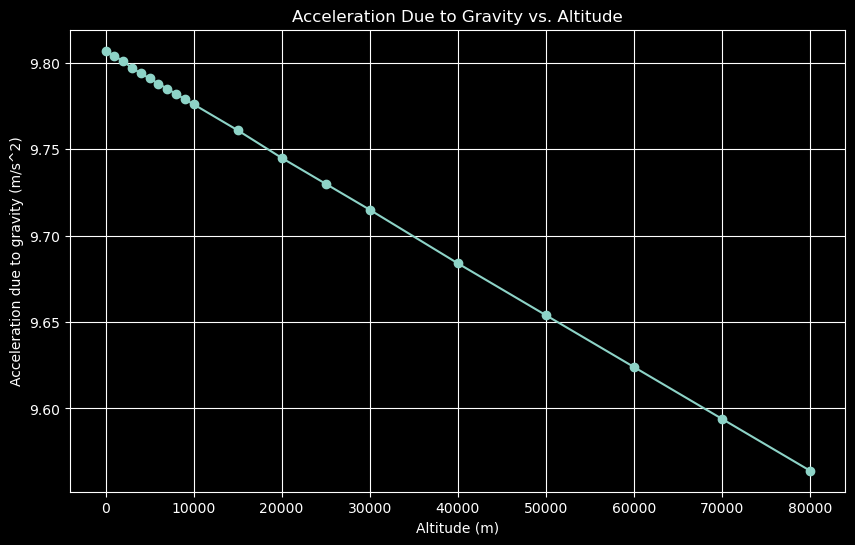

In [4]:
plt.figure(figsize=(10, 6))

plt.plot(altitude, gravity, 'o-')

plt.xlabel('Altitude (m)')
plt.ylabel('Acceleration due to gravity (m/s^2)')
plt.title('Acceleration Due to Gravity vs. Altitude')

plt.grid(True)
plt.show()

In [5]:
print("Gravity at lowest altitude =", gravity[0], "m/s^2")
print("Gravity at highest altitude =", gravity[-1], "m/s^2")

change = gravity[-1] - gravity[0]

print("Change in gravity =", change, "m/s^2")

Gravity at lowest altitude = 9.807 m/s^2
Gravity at highest altitude = 9.564 m/s^2
Change in gravity = -0.24300000000000033 m/s^2


In [6]:
percent_change = (gravity[-1] - gravity[0]) / gravity[0] * 100

print("Percent change in gravity =", percent_change, "%")

Percent change in gravity = -2.4778219639033376 %


**_Question_ #_3_**

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

def simulate_data(a, npoints, tmin, tmax, uncertainty):

    t = np.random.uniform(tmin, tmax, npoints)

    v = (a[0] + a[1]*t
         + a[2]*np.sin(a[4]*t)
         + a[3]*np.cos(a[4]*t))

    error = np.random.normal(0, uncertainty, npoints)

    v = v + error

    return t, v

Plotting data

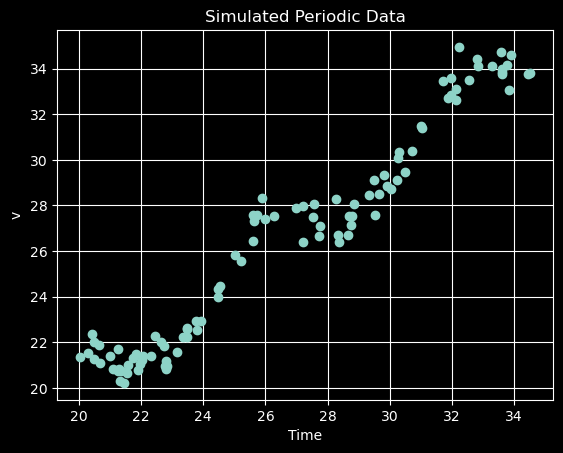

In [8]:
a = np.array([0.0, 1.0, 1.0, 1.0, 1.0])

t, v = simulate_data(a, 100, 20, 35, 0.5)

plt.plot(t, v, 'o')
plt.xlabel('Time')
plt.ylabel('v')
plt.title('Simulated Periodic Data')
plt.grid(True)
plt.show()

Defining fit function

In [9]:
def fit_function(t, a0, a1, a2, a3, a4):
    return (a0 + a1*t
            + a2*np.sin(a4*t)
            + a3*np.cos(a4*t))

initial_guess = [0, 1, 1, 1, 1]

popt, pcov = curve_fit(
    fit_function,
    t,
    v,
    p0=initial_guess
)

Uncertainty calculations

In [10]:
uncertainties = np.sqrt(np.diag(pcov))

for i in range(5):
    print("a", i, "=", popt[i], "+/-", uncertainties[i])

a 0 = -0.004113405882576671 +/- 0.4273350361170676
a 1 = 0.9997229709274943 +/- 0.015533479690319332
a 2 = 0.8149368298225654 +/- 0.44011941808617777
a 3 = 1.17301494550871 +/- 0.32691411694248224
a 4 = 0.9910946272661366 +/- 0.013803502478693544


Plotting

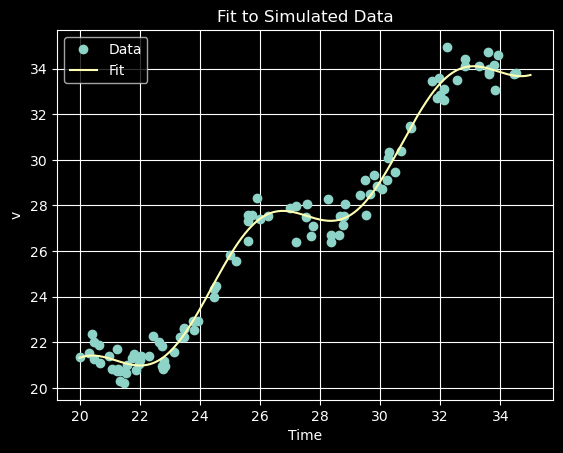

In [11]:
t_fit = np.linspace(20, 35, 500)
v_fit = fit_function(t_fit, *popt)

plt.plot(t, v, 'o', label='Data')
plt.plot(t_fit, v_fit, label='Fit')

plt.xlabel('Time')
plt.ylabel('v')
plt.title('Fit to Simulated Data')
plt.legend()
plt.grid(True)
plt.show()

The fitted parameters are consistent with the expected values within their uncertainties. The expected values are a0 = 0, a1 = 1, a2 = 1, a3 = 1, and a4 = 1. Because Gaussian measurement errors were added to the data, the fitted parameters are not quite equal to the input values, but they should agree with them within the calculated uncertainties.

In [12]:
def new_fit_function(t, a0, a1, a2, a3, a4):
    return a0 + a1*t + a2*np.sin(a3*t + a4)

initial_guess = [0, 1, 1, 1, 0]

popt_new, pcov_new = curve_fit(
    new_fit_function,
    t,
    v,
    p0=initial_guess
)

Uncertainties... again

In [13]:
uncertainties_new = np.sqrt(np.diag(pcov_new))

for i in range(5):
    print("a", i, "=", popt_new[i], "+/-", uncertainties_new[i])

a 0 = -0.004187280004633959 +/- 0.42725407753841194
a 1 = 0.9997256290098794 +/- 0.015531018647319565
a 2 = 1.4283122101210008 +/- 0.080123468105433
a 3 = 0.991096143267319 +/- 0.0138045212519736
a 4 = 0.9635682390447536 +/- 0.37974689585732674


Plotting fit with data

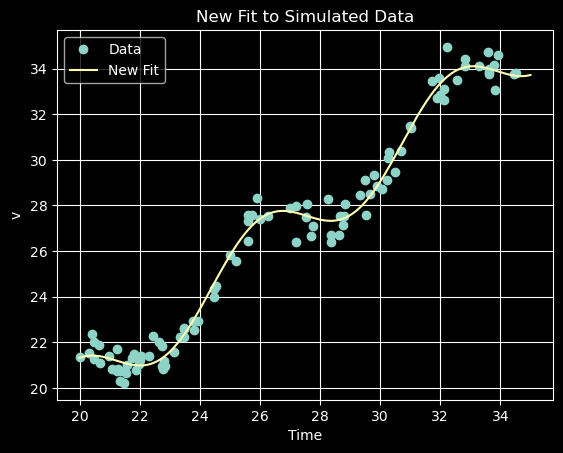

In [14]:
v_fit_new = new_fit_function(t_fit, *popt_new)

plt.plot(t, v, 'o', label='Data')
plt.plot(t_fit, v_fit_new, label='New Fit')

plt.xlabel('Time')
plt.ylabel('v')
plt.title('New Fit to Simulated Data')
plt.legend()
plt.grid(True)
plt.show()

Which is better?

Neither, they give equally accurate fits

In [15]:
residuals_old = (v - fit_function(t, *popt)) / 0.5
chi2_old = np.sum(residuals_old**2)

residuals_new = (v - new_fit_function(t, *popt_new)) / 0.5
chi2_new = np.sum(residuals_new**2)

print("Old chi^2 =", chi2_old)
print("New chi^2 =", chi2_new)

Old chi^2 = 107.40838660558991
New chi^2 = 107.40838660380794
